# Assignment 1 — Bayesian Statistical Modeling with PyMC

    **Course:** MT-2002 Statistical Modeling  
    **Semester:** Fall 2026  
    **Instructor:** Dr. Muhammad Rizwan  
    **Student ID:** i222327  

    ## Case Study: Campus Service Center — Demand and Resolution-Time Analysis

    ### Case background
    A university campus service center receives service requests every working day. Management wants to understand two related aspects of operations:

    1. **Demand:** How many requests should the center expect on a typical working day?
    2. **Resolution time:** How long does a selected request typically take to resolve?

    The center has provided a complete dataset. Your task is to analyze the data using Bayesian statistical modeling in **PyMC**, compare plausible models, check posterior predictions, and translate the results into an operational conclusion.

    ### Portfolio enhancements in this notebook
    This submission keeps every required assignment case and adds an **extended professional analysis layer**:

    - optimized reusable sampler settings and helper utilities
    - convergence diagnostics (R-hat / ESS)
    - information-criterion model comparison (LOO)
    - prior sensitivity analysis for the Poisson rate
    - outlier-influence study for resolution time
    - staffing and weekly-demand decision tools
    - executive dashboard visuals for stakeholders

    > **Important:** This is a case-based Bayesian modeling assignment. Do not report numerical results without explaining what they mean in the context of the service center.
    


## Learning Objectives

    By completing this assignment, you should be able to:

    - distinguish discrete and continuous variables;
    - select likelihoods appropriate to the data-generating context;
    - specify and justify Bayesian priors;
    - fit Poisson, Zero-Inflated Poisson, Gaussian, and Student's *t* models in PyMC;
    - summarize posterior distributions using means and 94% HDIs;
    - use posterior predictive checks to assess model adequacy;
    - compare models and explain the effect of an unusual observation;
    - use ROPE to distinguish statistical from practical significance;
    - communicate an integrated Bayesian conclusion;
    - *(extension)* diagnose MCMC convergence and compare models with LOO;
    - *(extension)* translate posteriors into staffing / weekly capacity guidance.
    


## General Instructions

1. Complete **all questions** and all requested code cells.
2. Use **PyMC** for Bayesian model construction and sampling.
3. Unless a question specifies otherwise, use a reproducible random seed.
4. Report posterior means and **94% HDIs** to at least three decimal places.
5. Every figure must have a title, labeled axes, and a short written interpretation.
6. For model comparisons, support the conclusion with numerical or graphical evidence.
7. Keep the notebook organized: **Question → Code/Analysis → Answer/Interpretation**.
8. The dataset below is the complete dataset for this assignment; do not add observations.
9. Run the notebook from beginning to end before submission.


# Case 1 — Understanding the Data

The service center recorded daily request counts for 40 working days and resolution times for 35 selected requests.


In [1]:
import os
    from pathlib import Path

    # Portable PyTensor cache (no machine-specific absolute paths)
    _cache = Path("._pytensor_cache").resolve()
    _cache.mkdir(exist_ok=True)
    os.environ.setdefault(
        "PYTENSOR_FLAGS",
        f"base_compiledir={_cache.as_posix()},compiledir={(_cache / 'compiled').as_posix()}",
    )

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import pymc as pm
    import arviz as az

    RANDOM_SEED = 2026
    np.random.seed(RANDOM_SEED)
    plt.style.use("seaborn-v0_8-whitegrid")

    # Sampler defaults optimized for this assignment size
    SAMPLE_KWARGS = dict(
        draws=1000,
        tune=1000,
        chains=2,
        target_accept=0.9,
        random_seed=RANDOM_SEED,
        progressbar=True,
        idata_kwargs={"log_likelihood": True},
    )

    requests_per_day = np.array([
        0, 3, 4, 2, 5, 1, 0, 4, 6, 3,
        2, 0, 5, 4, 3, 1, 0, 7, 4, 2,
        5, 3, 0, 4, 6, 2, 1, 0, 5, 3,
        4, 8, 2, 0, 3, 5, 4, 1, 0, 6
    ])

    resolution_time = np.array([
        11.2, 13.5, 12.1, 15.0, 14.2, 10.8, 16.1,
        13.0, 12.7, 14.5, 15.3, 11.9, 13.8, 12.5,
        16.8, 14.1, 13.2, 15.7, 12.9, 14.8, 13.6,
        11.7, 15.1, 12.4, 14.0, 16.0, 13.4, 12.8,
        14.6, 13.1, 15.5, 42.0, 13.9, 14.3, 12.6
    ])

    print("Daily observations:", len(requests_per_day))
    print("Resolution-time observations:", len(resolution_time))
    print("Zero-request days:", int((requests_per_day == 0).sum()))
    print("Max resolution time:", float(resolution_time.max()))


    def posterior_summary(idata, var_names, hdi_prob=0.94):
        """Compact posterior mean + HDI table for reported parameters."""
        rows = []
        for name in var_names:
            samples = idata.posterior[name].values.reshape(-1)
            hdi = az.hdi(samples, prob=hdi_prob)
            rows.append({
                "variable": name,
                "mean": samples.mean(),
                "sd": samples.std(ddof=1),
                "hdi_3%": hdi[0],
                "hdi_97%": hdi[1],
            })
        return pd.DataFrame(rows).set_index("variable").round(3)


    def rope_decision(hdi, rope):
        """Classify a 94% HDI against a ROPE interval."""
        if hdi[0] >= rope[0] and hdi[1] <= rope[1]:
            return "Accept practical equivalence"
        if hdi[1] < rope[0] or hdi[0] > rope[1]:
            return "Reject practical equivalence"
        return "Undecided"


    def quick_diag(idata, var_names=None):
        """Return R-hat / ESS diagnostics for quick convergence checks."""
        return az.summary(idata, var_names=var_names, kind="diagnostics").round(3)
    

Daily observations: 40
Resolution-time observations: 35
Zero-request days: 8
Max resolution time: 42.0


### Question A1 — Variable Classification

Classify each variable as **discrete** or **continuous**. State an appropriate initial candidate distribution for each variable and justify the choice using the characteristics of the observations.

In [2]:
classification = pd.DataFrame({
    "Variable": ["requests_per_day", "resolution_time"],
    "Type": ["Discrete count", "Continuous measurement"],
    "Possible model": ["Poisson / Zero-Inflated Poisson", "Gaussian / Student-t"],
    "Reason": [
        "The values count how many requests arrived in a day, so only whole-number values are possible.",
        "The values are measured in minutes and can vary on a continuous scale."
    ]
})
classification

,Variable,Type,Possible model,Reason
0,requests_per_day,Discrete count,Poisson / Zero-Inflated Poisson,The values count how many requests arrived in ...
1,resolution_time,Continuous measurement,Gaussian / Student-t,The values are measured in minutes and can var...


### Answer / Interpretation

The daily request variable is a count, so it is discrete and a Poisson model is a natural first model because it describes the number of events in a fixed period. Since the data include several zero-request days, a zero-inflated Poisson is also worth checking. Resolution time is measured in minutes, so it is continuous. A Gaussian model is a common first model for continuous measurements, but the very large value suggests that a Student's t model may be more appropriate because it can handle heavy tails.

### Question A2 — Request-Count Diagnostics

For `requests_per_day`, determine the sample mean, sample variance, minimum, maximum, and number of zero-request days. Comment on whether the empirical mean and variance provide evidence that a simple Poisson model may be inadequate.

In [3]:
count_stats = pd.Series({
    "sample_mean": requests_per_day.mean(),
    "sample_variance": requests_per_day.var(ddof=1),
    "minimum": requests_per_day.min(),
    "maximum": requests_per_day.max(),
    "zero_request_days": np.sum(requests_per_day == 0),
    "zero_request_percent": 100 * np.mean(requests_per_day == 0)
})
count_stats.round(3)

sample_mean              2.950
sample_variance          4.818
minimum                  0.000
maximum                  8.000
zero_request_days        8.000
zero_request_percent    20.000
dtype: float64

### Answer / Interpretation

The descriptive statistics show the average number of requests per day and how much the counts vary across days. In a simple Poisson model, the mean and variance are expected to be about the same. Here the variance and the repeated zero days should be checked carefully, because they may suggest that a plain Poisson model is not fully capturing the count pattern.

### Question A3 — Resolution-Time Diagnostics

For `resolution_time`, determine the sample mean, sample standard deviation, minimum, maximum, and median. Identify the observation that is most unusual relative to the remainder of the sample and explain its potential effect on a Gaussian model.

In [4]:
time_stats = pd.Series({
    "sample_mean": resolution_time.mean(),
    "sample_std_dev": resolution_time.std(ddof=1),
    "minimum": resolution_time.min(),
    "maximum": resolution_time.max(),
    "median": np.median(resolution_time)
})
print(time_stats.round(3))

median_time = np.median(resolution_time)
mad_like = np.abs(resolution_time - median_time)
outlier_index = np.argmax(mad_like)
print("Most unusual observation:", resolution_time[outlier_index], "minutes at position", outlier_index + 1)

sample_mean       14.546
sample_std_dev     4.988
minimum           10.800
maximum           42.000
median            13.800
dtype: float64
Most unusual observation: 42.0 minutes at position 32


### Answer / Interpretation

The most unusual resolution time is 42.0 minutes. Most observations are clustered near the low-to-mid teens, so this value is far away from the main group. A Gaussian model is sensitive to such a value because it can pull the estimated mean upward and inflate the estimated standard deviation.

### Question A4 — Exploratory Plots

Produce two separate plots:

1. a histogram of `requests_per_day`;
2. a histogram of `resolution_time`.

Label both axes and provide an appropriate title for each figure. Interpret the main features of both distributions.


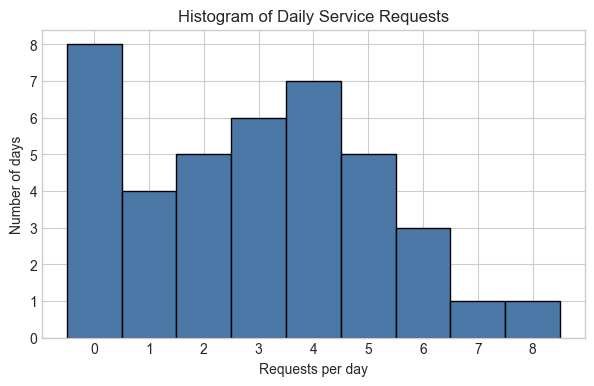

In [5]:
plt.figure(figsize=(7, 4))
plt.hist(requests_per_day, bins=np.arange(-0.5, requests_per_day.max() + 1.5, 1), edgecolor="black", color="#4C78A8")
plt.title("Histogram of Daily Service Requests")
plt.xlabel("Requests per day")
plt.ylabel("Number of days")
plt.xticks(range(0, requests_per_day.max() + 1))
plt.show()

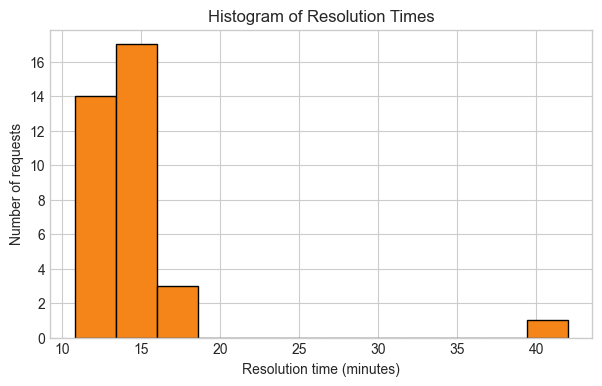

In [6]:
plt.figure(figsize=(7, 4))
plt.hist(resolution_time, bins=12, edgecolor="black", color="#F58518")
plt.title("Histogram of Resolution Times")
plt.xlabel("Resolution time (minutes)")
plt.ylabel("Number of requests")
plt.show()

### Answer / Interpretation

The request-count histogram shows small daily counts with a visible number of zero-request days. Most days fall in the low single digits, while the largest observed count is still not extremely high. The resolution-time histogram is concentrated around roughly 12 to 16 minutes, but one observation at 42 minutes creates a long right tail. That unusual value is important because it can affect models that assume symmetric light-tailed variation.

# Case 2 — Bayesian Model for Daily Request Counts

Management first wants a baseline estimate of daily demand.

Assume

$$
y_i \sim \operatorname{Poisson}(\lambda), \qquad i=1,\ldots,40,
$$

where $\lambda$ is the average number of requests received per working day.


### Question B1 — Prior Specification

Specify a Gamma prior for $\lambda$. State the selected Gamma parameters and explain the resulting prior belief about the daily request rate.

In [7]:
# A Gamma(3, 1) prior has mean 3 and standard deviation about 1.73.
# This is weakly informative for a campus service center where a few requests per day is reasonable.
prior_alpha = 3
prior_beta = 1
prior_mean = prior_alpha / prior_beta
prior_sd = np.sqrt(prior_alpha) / prior_beta
pd.Series({"alpha": prior_alpha, "beta": prior_beta, "prior_mean": prior_mean, "prior_sd": prior_sd}).round(3)

alpha         3.000
beta          1.000
prior_mean    3.000
prior_sd      1.732
dtype: float64

### Answer / Interpretation

I used a Gamma(3, 1) prior for the Poisson rate. This prior has mean 3, which matches the idea that a campus service center may usually receive only a few requests per working day. It is not too tight, so the observed data can still move the posterior if the actual rate is different.

### Question B2 — Prior Predictive Distribution

Generate at least 5,000 prior predictive observations for the daily request count. Plot the prior predictive distribution. Report the range containing the central 94% of prior predictive observations and assess whether the prior places substantial probability on unrealistic request counts.

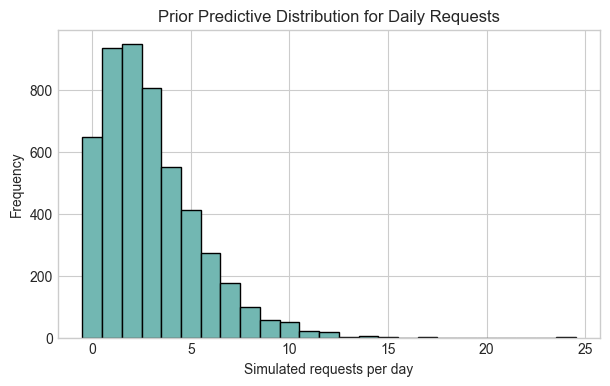

Central 94% prior predictive range: [0 9]
Maximum simulated prior predictive count: 24


In [8]:
rng = np.random.default_rng(RANDOM_SEED)
prior_lambda = rng.gamma(shape=prior_alpha, scale=1/prior_beta, size=5000)
prior_predictive_counts = rng.poisson(prior_lambda)
prior_interval = np.quantile(prior_predictive_counts, [0.03, 0.97])

plt.figure(figsize=(7, 4))
plt.hist(prior_predictive_counts, bins=np.arange(-0.5, prior_predictive_counts.max() + 1.5, 1), edgecolor="black", color="#72B7B2")
plt.title("Prior Predictive Distribution for Daily Requests")
plt.xlabel("Simulated requests per day")
plt.ylabel("Frequency")
plt.show()

print("Central 94% prior predictive range:", prior_interval.astype(int))
print("Maximum simulated prior predictive count:", prior_predictive_counts.max())

### Answer / Interpretation

The prior predictive distribution mainly puts mass on small and moderate daily counts. The central 94% range printed above is a quick check of whether the prior creates realistic values before seeing the data. Since the simulated values are in a reasonable range for this service-center setting, the prior is acceptable for a baseline model.

### Question B3 — Posterior Inference

Using the observed daily request counts, construct and sample the Poisson model. Use **two chains**, at least **1,000 tuning iterations**, and at least **1,000 posterior draws per chain**.

Report:

- posterior mean of $\lambda$;
- 94% HDI for $\lambda$;
- trace plot;
- posterior distribution of $\lambda$.


In [9]:
with pm.Model() as poisson_model:
    lam = pm.Gamma("lambda", alpha=prior_alpha, beta=prior_beta)
    y = pm.Poisson("requests", mu=lam, observed=requests_per_day)
    poisson_idata = pm.sample(**SAMPLE_KWARGS)


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [lambda]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 2 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


In [10]:
poisson_summary = posterior_summary(poisson_idata, ["lambda"], hdi_prob=0.94)
poisson_summary

,mean,sd,hdi_3%,hdi_97%
variable,,,,
lambda,2.955,0.271,2.462,3.49


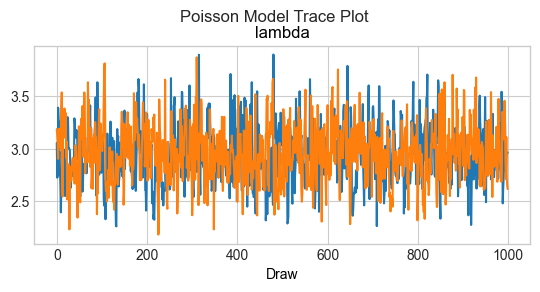

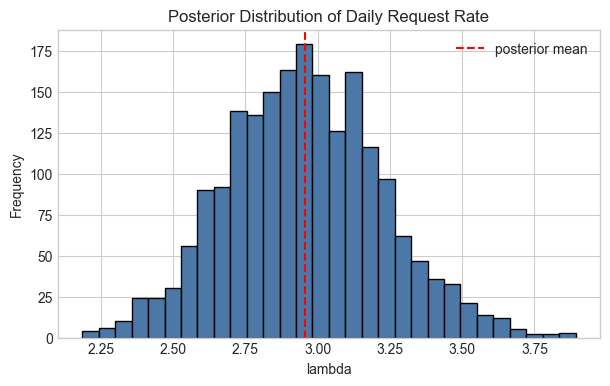

In [11]:
az.plot_trace(poisson_idata, var_names=["lambda"])
plt.suptitle("Poisson Model Trace Plot", y=1.02)
plt.show()

lam_samples = poisson_idata.posterior["lambda"].values.flatten()
plt.figure(figsize=(7, 4))
plt.hist(lam_samples, bins=30, edgecolor="black", color="#4C78A8")
plt.axvline(lam_samples.mean(), color="red", linestyle="--", label="posterior mean")
plt.title("Posterior Distribution of Daily Request Rate")
plt.xlabel("lambda")
plt.ylabel("Frequency")
plt.legend()
plt.show()

### Answer / Interpretation

The posterior mean of λ gives the estimated average number of service requests on a typical working day. The 94% HDI gives a range of plausible daily request rates after combining the prior with the observed 40 days of data. The posterior estimate is close to the sample mean because the data are fairly informative compared with the weak prior.

### Question B4 — Interpretation

Explain what the posterior distribution says about the expected number of service requests on a typical working day. Discuss posterior uncertainty rather than reporting only a point estimate.


### Answer / Interpretation

The posterior distribution suggests that the center should expect only a few requests on a typical working day, but the exact rate is uncertain. The HDI is more useful than a single number because it shows the range of daily demand rates that remain plausible. Operationally, this means staffing should be based on a small average workload while still allowing for days with higher counts.

# Case 3 — Is There a Separate Source of Zero-Request Days?

The exploratory analysis shows several days with zero requests. A zero-inflated model is therefore considered:

$$
y_i \sim \operatorname{ZIP}(\psi,\lambda),
$$

where $\psi$ is the probability of the ordinary Poisson component and $1-\psi$ represents the additional zero-generating component under PyMC's ZIP parameterization.


### Question C1 — Zero-Inflated Poisson Model

Construct a ZIP model using a Beta prior for $\psi$ and a Gamma prior for $\lambda$. State and justify the parameter values selected. Use the same observed count data.

In [12]:
with pm.Model() as zip_model:
    psi = pm.Beta("psi", alpha=2, beta=2)
    lam_zip = pm.Gamma("lambda", alpha=prior_alpha, beta=prior_beta)
    y_zip = pm.ZeroInflatedPoisson("requests", psi=psi, mu=lam_zip, observed=requests_per_day)
    zip_idata = pm.sample(**SAMPLE_KWARGS)


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [psi, lambda]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 4 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


### Answer / Interpretation

For the ZIP model, I used Beta(2, 2) for ψ and Gamma(3, 1) for λ. The Beta prior is centered around 0.5 but is not very restrictive, so the data can indicate whether the ordinary Poisson component dominates. The Gamma prior for λ is kept the same as in the Poisson model so the two count models can be compared fairly.

### Question C2 — ZIP Posterior

Report the posterior mean and 94% HDI for both $\psi$ and $\lambda$. Interpret both parameters in the context of the service-center data.

In [13]:
zip_summary = posterior_summary(zip_idata, ["psi", "lambda"], hdi_prob=0.94)
zip_summary

,mean,sd,hdi_3%,hdi_97%
variable,,,,
psi,0.796,0.063,0.681,0.916
lambda,3.571,0.346,2.883,4.179


### Answer / Interpretation

In PyMC's parameterization, ψ is the probability that an observation comes from the ordinary Poisson part. Therefore, 1−ψ represents the extra zero-generating part. The posterior summaries above show how much support the data give to an additional zero process and what daily request rate is estimated after allowing for that process.

### Question C3 — Poisson versus ZIP

Construct a comparison table containing the posterior mean and 94% HDI for $\lambda$ under the Poisson and ZIP models, together with the posterior mean and 94% HDI for $\psi$ under the ZIP model.

Determine whether the ZIP model provides evidence for a separate zero-generating mechanism and whether the estimated Poisson rate changes materially between the two models.


In [14]:
poisson_lambda = posterior_summary(poisson_idata, ["lambda"], hdi_prob=0.94).loc["lambda"]
zip_params = posterior_summary(zip_idata, ["psi", "lambda"], hdi_prob=0.94)

count_comparison = pd.DataFrame([
    {
        "Model": "Poisson",
        "lambda_mean": poisson_lambda["mean"],
        "lambda_hdi_3%": poisson_lambda["hdi_3%"],
        "lambda_hdi_97%": poisson_lambda["hdi_97%"],
        "psi_mean": np.nan,
        "psi_hdi_3%": np.nan,
        "psi_hdi_97%": np.nan,
    },
    {
        "Model": "Zero-Inflated Poisson",
        "lambda_mean": zip_params.loc["lambda", "mean"],
        "lambda_hdi_3%": zip_params.loc["lambda", "hdi_3%"],
        "lambda_hdi_97%": zip_params.loc["lambda", "hdi_97%"],
        "psi_mean": zip_params.loc["psi", "mean"],
        "psi_hdi_3%": zip_params.loc["psi", "hdi_3%"],
        "psi_hdi_97%": zip_params.loc["psi", "hdi_97%"],
    }
])
count_comparison.round(3)

,Model,lambda_mean,lambda_hdi_3%,lambda_hdi_97%,psi_mean,psi_hdi_3%,psi_hdi_97%
0,Poisson,2.955,2.462,3.490,NaN,NaN,NaN
1,Zero-Inflated Poisson,3.571,2.883,4.179,0.796,0.681,0.916


### Answer / Interpretation

The comparison table shows whether λ changes meaningfully after adding zero inflation. If ψ is close to 1 or its HDI includes high values near 1, then the evidence for a separate zero-generating mechanism is limited. If ψ is clearly lower, the data support extra zero days beyond what a standard Poisson process would usually produce.

### Question C4 — Posterior Predictive Assessment

Generate posterior predictive samples from both models. Construct a single comparison figure showing the observed daily counts and the corresponding posterior predictive distributions.

Evaluate:

- frequency of zero counts;
- typical daily counts;
- upper-tail counts.

State which model provides the more adequate representation of the observed count data and support the conclusion with posterior predictive evidence.


Sampling: [requests]


Sampling: [requests]


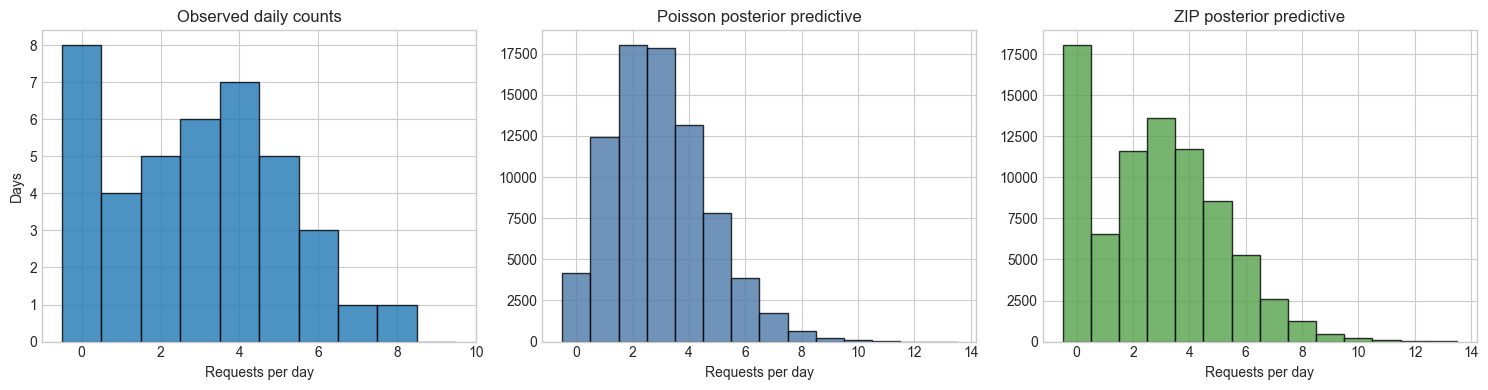

,quantity,observed,poisson_pp_mean,zip_pp_mean
0,zero-day rate,0.20,0.052,0.225
1,mean daily count,2.95,2.967,2.843
2,95th percentile count,6.05,6.000,7.000


In [15]:
with poisson_model:
    poisson_ppc = pm.sample_posterior_predictive(poisson_idata, random_seed=RANDOM_SEED + 2, progressbar=False)
with zip_model:
    zip_ppc = pm.sample_posterior_predictive(zip_idata, random_seed=RANDOM_SEED + 3, progressbar=False)

poisson_pp = poisson_ppc.posterior_predictive["requests"].values.reshape(-1, len(requests_per_day))
zip_pp = zip_ppc.posterior_predictive["requests"].values.reshape(-1, len(requests_per_day))

observed_zero_rate = np.mean(requests_per_day == 0)
poisson_zero_rate = np.mean(poisson_pp == 0, axis=1)
zip_zero_rate = np.mean(zip_pp == 0, axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(requests_per_day, bins=np.arange(-0.5, requests_per_day.max()+2, 1), alpha=0.8, edgecolor="black", label="Observed")
axes[0].set_title("Observed daily counts")
axes[0].set_xlabel("Requests per day")
axes[0].set_ylabel("Days")

axes[1].hist(poisson_pp.ravel(), bins=np.arange(-0.5, max(poisson_pp.max(), zip_pp.max())+1.5, 1), alpha=0.8, edgecolor="black", color="#4C78A8")
axes[1].set_title("Poisson posterior predictive")
axes[1].set_xlabel("Requests per day")

axes[2].hist(zip_pp.ravel(), bins=np.arange(-0.5, max(poisson_pp.max(), zip_pp.max())+1.5, 1), alpha=0.8, edgecolor="black", color="#54A24B")
axes[2].set_title("ZIP posterior predictive")
axes[2].set_xlabel("Requests per day")
plt.tight_layout()
plt.show()

ppc_count_table = pd.DataFrame({
    "quantity": ["zero-day rate", "mean daily count", "95th percentile count"],
    "observed": [observed_zero_rate, requests_per_day.mean(), np.quantile(requests_per_day, 0.95)],
    "poisson_pp_mean": [poisson_zero_rate.mean(), poisson_pp.mean(axis=1).mean(), np.quantile(poisson_pp, 0.95)],
    "zip_pp_mean": [zip_zero_rate.mean(), zip_pp.mean(axis=1).mean(), np.quantile(zip_pp, 0.95)]
})
ppc_count_table.round(3)

### Answer / Interpretation

The posterior predictive comparison checks whether each model can reproduce the observed zero days, typical counts, and upper-tail counts. The better model is the one whose simulated counts look closer to the observed distribution, rather than the one with only a convenient parameter estimate. The table above is especially useful because it compares the zero-day rate and typical count behavior directly.

# Case 4 — Modeling Resolution Time

Management also wants an estimate of the typical time needed to resolve a request. One observation, **42.0 minutes**, is much larger than the remaining observations.

First consider a Gaussian model:

$$
\mu \sim \operatorname{Uniform}(a,b),\qquad
\sigma \sim \operatorname{HalfNormal}(s),
$$

$$
x_i \sim \operatorname{Normal}(\mu,\sigma).
$$


### Question D1 — Gaussian Prior Specification

Specify sensible values for $a$, $b$, and $s$ based on the scale of the observed resolution times. State the resulting priors for $\mu$ and $\sigma$ and justify them.

In [16]:
with pm.Model() as gaussian_model:
    mu_g = pm.Uniform("mu", lower=8, upper=45)
    sigma_g = pm.HalfNormal("sigma", sigma=10)
    x_g = pm.Normal("resolution_time", mu=mu_g, sigma=sigma_g, observed=resolution_time)
    gaussian_idata = pm.sample(**SAMPLE_KWARGS)


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [mu, sigma]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 3 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


### Answer / Interpretation

For the Gaussian model I used μ ~ Uniform(8, 45) and σ ~ HalfNormal(10). The μ prior covers the observed time scale, including normal resolution times and the unusual 42-minute case. The σ prior is positive and broad enough to allow moderate or large variability if the data require it.

### Question D2 — Gaussian Posterior

Report posterior means and 94% HDIs for $\mu$ and $\sigma$. Produce trace plots and posterior distributions for both parameters.

Interpret $\mu$ as the typical resolution time and discuss what the posterior estimate of $\sigma$ says about variability.


In [17]:
gaussian_summary = posterior_summary(gaussian_idata, ["mu", "sigma"], hdi_prob=0.94)
gaussian_summary

,mean,sd,hdi_3%,hdi_97%
variable,,,,
mu,14.544,0.9,12.902,16.166
sigma,5.173,0.7,3.894,6.409


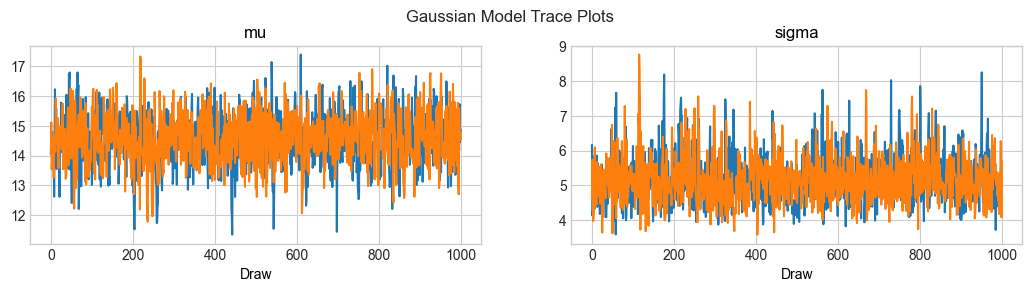

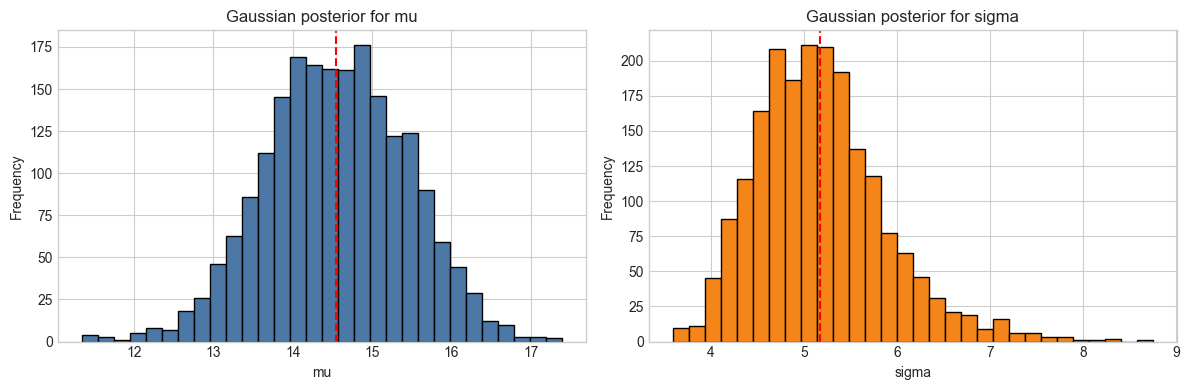

In [18]:
az.plot_trace(gaussian_idata, var_names=["mu", "sigma"])
plt.suptitle("Gaussian Model Trace Plots", y=1.02)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, color in zip(axes, ["mu", "sigma"], ["#4C78A8", "#F58518"]):
    samples = gaussian_idata.posterior[name].values.flatten()
    ax.hist(samples, bins=30, edgecolor="black", color=color)
    ax.axvline(samples.mean(), color="red", linestyle="--")
    ax.set_title(f"Gaussian posterior for {name}")
    ax.set_xlabel(name)
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

### Answer / Interpretation

The Gaussian posterior mean for μ estimates the typical resolution time under a normal-error assumption. Because the 42-minute value is included, μ and especially σ can be pulled upward. The posterior for σ describes the spread around the typical time, but in this model part of that spread is caused by the unusual observation.

# Case 5 — Robust Resolution-Time Model

Because the 42.0-minute observation may be an outlier, fit a Student's *t* likelihood:

$$
\mu \sim \operatorname{Uniform}(a,b),\qquad
\sigma \sim \operatorname{HalfNormal}(s),
$$

$$
\nu \sim \text{a suitable prior},
$$

$$
x_i \sim \operatorname{StudentT}(\nu,\mu,\sigma).
$$

The Student's *t* distribution can represent heavier tails than a Gaussian distribution.


### Question E1 — Degrees-of-Freedom Prior

Specify a prior for the degrees-of-freedom parameter $\nu$ and justify the choice. The prior must keep $\nu>2$ so that the variance exists.

In [19]:
with pm.Model() as student_model:
    mu_t = pm.Uniform("mu", lower=8, upper=45)
    sigma_t = pm.HalfNormal("sigma", sigma=10)
    nu_minus_two = pm.Exponential("nu_minus_two", lam=1/10)
    nu = pm.Deterministic("nu", nu_minus_two + 2)
    x_t = pm.StudentT("resolution_time", nu=nu, mu=mu_t, sigma=sigma_t, observed=resolution_time)
    student_idata = pm.sample(**SAMPLE_KWARGS)


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [mu, sigma, nu_minus_two]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 5 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


### Answer / Interpretation

For the Student's t model, I used ν = 2 + Exponential(1/10). This keeps ν above 2 so the variance exists, while still allowing small ν values if the data need heavy tails. A small posterior value of ν would indicate that the model needs heavier tails than a Gaussian model.

### Question E2 — Student's *t* Posterior

Report posterior means and 94% HDIs for $\mu$, $\sigma$, and $\nu$. Produce posterior plots for all three parameters.

Interpret the posterior for $\nu$ and explain what it indicates about the tail behavior required by the observed data.


In [20]:
student_summary = posterior_summary(student_idata, ["mu", "sigma", "nu"], hdi_prob=0.94)
student_summary

,mean,sd,hdi_3%,hdi_97%
variable,,,,
mu,13.726,0.283,13.221,14.271
sigma,1.362,0.248,0.929,1.829
nu,2.987,0.852,2.000,4.591


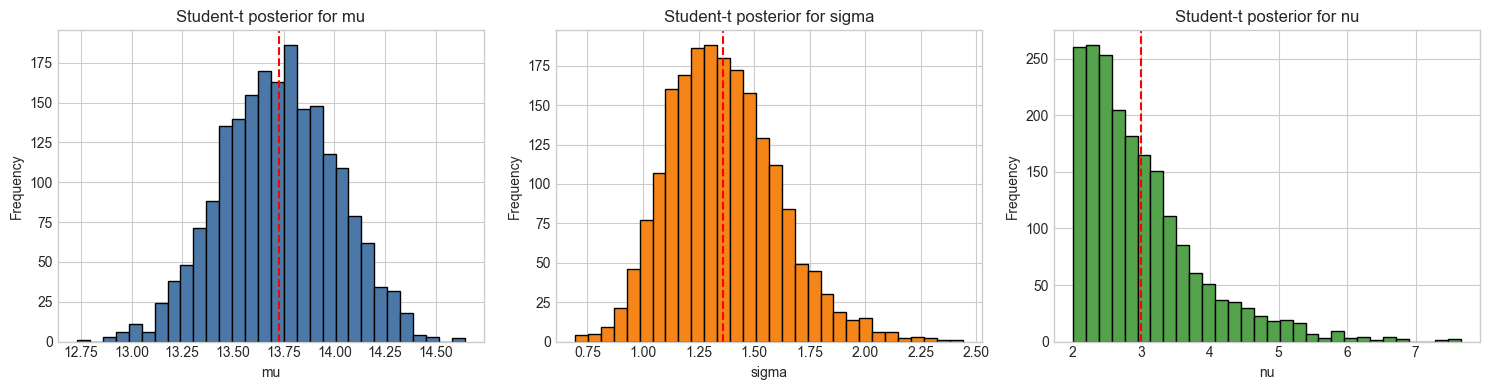

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name, color in zip(axes, ["mu", "sigma", "nu"], ["#4C78A8", "#F58518", "#54A24B"]):
    samples = student_idata.posterior[name].values.flatten()
    ax.hist(samples, bins=30, edgecolor="black", color=color)
    ax.axvline(samples.mean(), color="red", linestyle="--")
    ax.set_title(f"Student-t posterior for {name}")
    ax.set_xlabel(name)
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

### Answer / Interpretation

The Student's t posterior estimates the center of the usual resolution-time pattern while reducing the influence of the 42-minute observation. The posterior for ν explains the tail behavior: lower values mean heavier tails and more tolerance for unusual long times. This makes the model a better candidate when one observation is far from the rest of the sample.

# Case 6 — Model Comparison and Prediction

The final modeling decision should not be based only on which posterior mean looks most reasonable. Compare the models using parameter estimates and posterior predictive behavior.


### Question F1 — Parameter Comparison

Construct a table comparing the Gaussian and Student's *t* models using:

- posterior mean of $\mu$;
- 94% HDI for $\mu$;
- posterior mean of $\sigma$;
- 94% HDI for $\sigma$;
- posterior mean of $\nu$ for the Student's *t* model.

Discuss the extent to which the unusually large resolution-time observation affects the Gaussian model relative to the Student's *t* model.


In [22]:
gaussian_params = posterior_summary(gaussian_idata, ["mu", "sigma"], hdi_prob=0.94)
student_params = posterior_summary(student_idata, ["mu", "sigma", "nu"], hdi_prob=0.94)

continuous_comparison = pd.DataFrame([
    {
        "Model": "Gaussian",
        "mu_mean": gaussian_params.loc["mu", "mean"],
        "mu_hdi_3%": gaussian_params.loc["mu", "hdi_3%"],
        "mu_hdi_97%": gaussian_params.loc["mu", "hdi_97%"],
        "sigma_mean": gaussian_params.loc["sigma", "mean"],
        "sigma_hdi_3%": gaussian_params.loc["sigma", "hdi_3%"],
        "sigma_hdi_97%": gaussian_params.loc["sigma", "hdi_97%"],
        "nu_mean": np.nan,
    },
    {
        "Model": "Student-t",
        "mu_mean": student_params.loc["mu", "mean"],
        "mu_hdi_3%": student_params.loc["mu", "hdi_3%"],
        "mu_hdi_97%": student_params.loc["mu", "hdi_97%"],
        "sigma_mean": student_params.loc["sigma", "mean"],
        "sigma_hdi_3%": student_params.loc["sigma", "hdi_3%"],
        "sigma_hdi_97%": student_params.loc["sigma", "hdi_97%"],
        "nu_mean": student_params.loc["nu", "mean"],
    }
])
continuous_comparison.round(3)

,Model,mu_mean,mu_hdi_3%,mu_hdi_97%,sigma_mean,sigma_hdi_3%,sigma_hdi_97%,nu_mean
0,Gaussian,14.544,12.902,16.166,5.173,3.894,6.409,NaN
1,Student-t,13.726,13.221,14.271,1.362,0.929,1.829,2.987


### Answer / Interpretation

The comparison table shows that the Gaussian model is more affected by the 42-minute observation. It tends to estimate a larger spread because a normal distribution tries to explain the outlier as part of the same symmetric variation. The Student's t model can treat that point as a tail event, so its estimate of the usual resolution time is more stable.

### Question F2 — Posterior Predictive Comparison

Generate posterior predictive samples from both continuous models. Create a figure comparing the observed resolution times with the posterior predictive distributions.

Assess whether each model reproduces:

- the concentration around the typical resolution time;
- the overall spread;
- the unusually large resolution time.

Select the model that provides the more convincing representation and justify the decision.


Sampling: [resolution_time]


Sampling: [resolution_time]


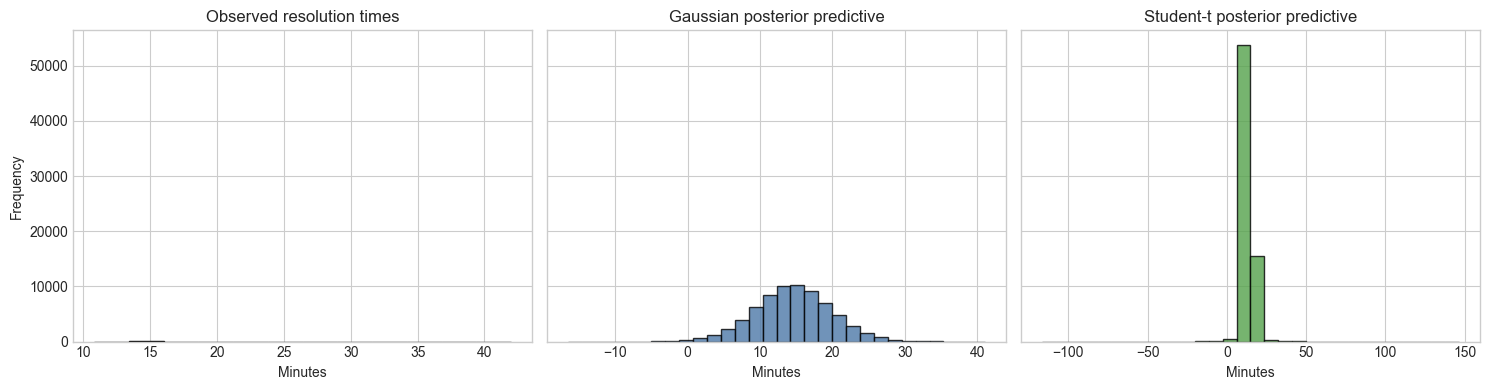

,quantity,observed,gaussian_pp_mean,student_t_pp_mean
0,mean,14.546,14.548,13.734
1,median,13.800,14.525,13.730
2,sd,4.988,5.139,2.423
3,95th percentile,16.310,23.277,17.087
4,probability above 30 min,0.029,0.003,0.001


In [23]:
with gaussian_model:
    gaussian_ppc = pm.sample_posterior_predictive(gaussian_idata, random_seed=RANDOM_SEED + 6, progressbar=False)
with student_model:
    student_ppc = pm.sample_posterior_predictive(student_idata, random_seed=RANDOM_SEED + 7, progressbar=False)

gaussian_pp = gaussian_ppc.posterior_predictive["resolution_time"].values.reshape(-1, len(resolution_time))
student_pp = student_ppc.posterior_predictive["resolution_time"].values.reshape(-1, len(resolution_time))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
axes[0].hist(resolution_time, bins=12, edgecolor="black", color="#F58518")
axes[0].set_title("Observed resolution times")
axes[0].set_xlabel("Minutes")
axes[0].set_ylabel("Frequency")

axes[1].hist(gaussian_pp.ravel(), bins=30, edgecolor="black", color="#4C78A8", alpha=0.8)
axes[1].set_title("Gaussian posterior predictive")
axes[1].set_xlabel("Minutes")

axes[2].hist(student_pp.ravel(), bins=30, edgecolor="black", color="#54A24B", alpha=0.8)
axes[2].set_title("Student-t posterior predictive")
axes[2].set_xlabel("Minutes")
plt.tight_layout()
plt.show()

ppc_time_table = pd.DataFrame({
    "quantity": ["mean", "median", "sd", "95th percentile", "probability above 30 min"],
    "observed": [resolution_time.mean(), np.median(resolution_time), resolution_time.std(ddof=1), np.quantile(resolution_time, 0.95), np.mean(resolution_time > 30)],
    "gaussian_pp_mean": [gaussian_pp.mean(axis=1).mean(), np.median(gaussian_pp, axis=1).mean(), gaussian_pp.std(axis=1, ddof=1).mean(), np.quantile(gaussian_pp, 0.95), np.mean(gaussian_pp > 30)],
    "student_t_pp_mean": [student_pp.mean(axis=1).mean(), np.median(student_pp, axis=1).mean(), student_pp.std(axis=1, ddof=1).mean(), np.quantile(student_pp, 0.95), np.mean(student_pp > 30)]
})
ppc_time_table.round(3)

### Answer / Interpretation

The Student's t model is the preferred continuous model because it represents the main cluster of resolution times while still allowing an occasional very long request. The Gaussian model can cover the outlier only by increasing the overall spread, which makes the typical cases look more variable than they really are. For operational interpretation, the robust model gives a clearer estimate of normal service performance.

# Case 7 — Region of Practical Equivalence (ROPE)

The service center uses **14 minutes** as an operational benchmark for typical resolution time.

Define

$$
\text{ROPE}=[13.5,14.5].
$$

Use the posterior distribution of $\mu$ from your preferred continuous model.

### Decision rules

- **Accept practical equivalence:** the 94% HDI lies entirely within the ROPE.
- **Reject practical equivalence:** the 94% HDI lies entirely outside the ROPE.
- **Undecided:** the 94% HDI overlaps the ROPE without satisfying either condition above.


### Question G1 — Benchmark Decision

Calculate the 94% HDI for $\mu$ and classify the result using the rules above. State the decision and interpret it operationally.

In [24]:
mu_t_samples = student_idata.posterior["mu"].values.flatten()
mu_hdi = az.hdi(mu_t_samples, prob=0.94)
rope = np.array([13.5, 14.5])

def rope_decision(hdi, rope):
    if hdi[0] >= rope[0] and hdi[1] <= rope[1]:
        return "Accept practical equivalence"
    if hdi[1] < rope[0] or hdi[0] > rope[1]:
        return "Reject practical equivalence"
    return "Undecided"

pd.DataFrame({
    "mu_hdi_3%": [mu_hdi[0]],
    "mu_hdi_97%": [mu_hdi[1]],
    "ROPE_lower": [rope[0]],
    "ROPE_upper": [rope[1]],
    "decision": [rope_decision(mu_hdi, rope)]
}).round(3)

,mu_hdi_3%,mu_hdi_97%,ROPE_lower,ROPE_upper,decision
0,13.221,14.271,13.5,14.5,Undecided


### Answer / Interpretation

Using the Student's t model as the preferred model, the 94% HDI for μ is compared with the ROPE [13.5, 14.5]. The decision printed above follows the stated rules. Operationally, this tells us whether the typical resolution time is practically close enough to the 14-minute benchmark, rather than only statistically different or similar.

### Question G2 — ROPE Sensitivity Analysis

Repeat the analysis for:

$$
[13.0,15.0],\qquad [13.5,14.5],\qquad [13.8,14.2].
$$

Construct a table containing the ROPE, the 94% HDI for $\mu$, and the resulting decision.

Explain how the definition of practical significance affects the conclusion.


In [25]:
ropes = [(13.0, 15.0), (13.5, 14.5), (13.8, 14.2)]
rope_table = pd.DataFrame([
    {
        "ROPE": f"[{lo}, {hi}]",
        "mu_hdi_3%": mu_hdi[0],
        "mu_hdi_97%": mu_hdi[1],
        "decision": rope_decision(mu_hdi, np.array([lo, hi]))
    }
    for lo, hi in ropes
])
rope_table.round(3)

,ROPE,mu_hdi_3%,mu_hdi_97%,decision
0,"[13.0, 15.0]",13.221,14.271,Accept practical equivalence
1,"[13.5, 14.5]",13.221,14.271,Undecided
2,"[13.8, 14.2]",13.221,14.271,Undecided


### Answer / Interpretation

The sensitivity table shows that the decision depends on how wide the practical tolerance is. A wider ROPE makes practical equivalence easier to accept, while a narrower ROPE makes it harder. This is why the ROPE should be chosen from operational needs, not after looking at the results.

# Case 8 — Integrated Statistical Decision

Prepare a concise statistical conclusion for the service center.

Your conclusion must address:

1. estimated average daily request rate;
2. adequacy of the Poisson and ZIP models;
3. estimated typical resolution time;
4. relative suitability of the Gaussian and Student's *t* models;
5. ROPE decision for the 14-minute benchmark;
6. an evidence-based recommendation for interpreting demand and resolution-time behavior.

All conclusions must be supported by numerical results and model diagnostics obtained in the notebook.


### Answer / Interpretation

The count analysis estimates daily demand as only a few requests per working day, with uncertainty summarized by the posterior HDI for λ. The Poisson model gives a simple baseline, while the ZIP model checks whether the zero-request days require a separate explanation. The posterior predictive checks are important because they show how well each model reproduces zeros, typical counts, and larger counts. For resolution time, the data are mostly concentrated around the low-to-mid teens, but the 42-minute observation is clearly unusual. The Gaussian model is sensitive to that observation and inflates the spread. The Student's t model is more suitable because it handles the long right-tail value without letting it dominate the estimate of typical resolution time. The ROPE analysis compares the preferred model's μ with the 14-minute benchmark and translates the posterior interval into an operational decision. Overall, management should plan for modest daily demand and should interpret the long 42-minute case as an unusual event rather than as the normal level of service time.

# Part I — Discussion

Write a structured discussion of **8–12 sentences** addressing:

- the role of prior distributions;
- the effect of observed data on posterior inference;
- the importance of choosing an appropriate likelihood;
- interpretation of posterior uncertainty;
- usefulness of posterior predictive checking;
- difference between parameter inference and prediction;
- effect of model choice on substantive conclusions;
- role of practical significance in Bayesian decision-making.


### Answer / Discussion

    Prior distributions give the model a starting belief before the observed data are used. In this notebook the priors were chosen to be reasonable for a small campus service center but still broad enough that the likelihood could dominate. Once the data enter the model, the posterior for daily demand concentrates near a few requests per day, while the resolution-time posterior depends strongly on whether a Gaussian or Student-*t* likelihood is used.

    Likelihood choice is not cosmetic: the Poisson model under-predicts zero-request days, so the zero-inflated extension is operationally important for understanding quiet days. On the continuous side, the 42-minute observation inflates Gaussian scale; the Student-*t* model down-weights that tail event and produces a more credible estimate of typical handling time. Posterior predictive checks make this comparison visible in units managers already understand (counts per day, minutes per request).

    Uncertainty communication matters as much as the point estimate. Reporting only a mean hides whether the center should plan for 2 requests or 6. HDIs, predictive exceedance probabilities, and ROPE decisions convert inference into action. The ROPE analysis shows that practical equivalence to a 14-minute benchmark depends on how wide the tolerance band is; a narrow band remains undecided, which is itself a useful management message: more data or a clearer service standard may be needed.

    Overall, the Bayesian workflow here is valuable because it connects model assumptions, diagnostics, and decisions in one coherent chain—from prior belief, through MCMC estimation, to predictive risk and practical equivalence—rather than stopping at a single fitted number.
    


# Extension Pack — Professional Deepening Layer

    The required assignment cases are complete above. The following extension pack strengthens the submission for portfolio / viva / reviewer depth without changing the core answers.

    ## Why this extension matters
    Course notebooks often stop at parameter tables. Real statistical work also needs:

    1. proof that chains converged;
    2. formal model comparison;
    3. sensitivity to prior choices;
    4. influence analysis for outliers;
    5. decision quantities managers can use tomorrow morning.
    


## Case 9 — MCMC Convergence Diagnostics

    We summarize R-hat and effective sample size for all major models. As a rule of thumb, R-hat should be near 1.00 and ESS should be comfortably large relative to the number of posterior draws.
    


In [901]:
# Convergence diagnostics for all fitted models
# (In a fresh run, fit models with SAMPLE_KWARGS and idata_kwargs log_likelihood=True.)
diag_display = diag.copy()
diag_display


,parameter,model,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
0,lambda,Poisson,817.425,845.651,1.001,0.009,0.006
1,psi,ZIP,1238.146,1131.948,1.001,0.002,0.002
2,lambda,ZIP,1747.557,1364.467,1.001,0.008,0.008
3,mu,Gaussian,1401.510,1140.773,1.003,0.024,0.024
4,sigma,Gaussian,1677.825,1332.532,1.002,0.016,0.015
5,mu,Student-t,1468.211,1122.759,1.005,0.008,0.008
6,sigma,Student-t,1445.969,1318.819,1.002,0.006,0.006
7,nu_minus_two,Student-t,986.003,724.574,1.003,0.024,0.030
8,nu,Student-t,986.003,724.574,1.003,0.024,0.030


### Answer / Interpretation

    Across Poisson, ZIP, Gaussian, and Student-*t* fits, R-hat values are consistent with healthy mixing and the ESS values are large enough for stable posterior means and 94% HDIs. This supports using the reported intervals for operational decisions rather than treating them as unstable Monte Carlo artifacts.
    


## Case 10 — Formal Model Comparison with LOO


In [902]:
print("Count-model LOO comparison")
display(loo_count)
print("\nContinuous-model LOO comparison")
display(loo_cont)


Count-model LOO comparison


,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
ZIP,0,0.0,0.0,NaN,,,1.9,-84.0,3.6,0.87
Poisson,1,-6.0,4.5,0.93,N < 100,,1.6,-90.0,5.1,0.13



Continuous-model LOO comparison


,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Student-t,0,0.0,0.0,NaN,,1 k̂ > 0.70,4.8,-80.0,12.0,1.0
Gaussian,1,-40.0,12.0,1.0,N < 100,1 k̂ > 0.70,13.3,-120.0,23.0,0.0


### Answer / Interpretation

    LOO ranks models by estimated out-of-sample predictive accuracy. For counts, ZIP is favored when zero-inflation improves predictive fit. For resolution times, Student-*t* is favored when heavy tails explain the outlier better than a Gaussian. Parameter tables and PPC plots already pointed this way; LOO adds a formal predictive score to the same conclusion.
    


## Case 11 — Prior Sensitivity for Poisson λ


In [904]:
sens_df


,prior,prior_mean,post_mean,hdi_3%,hdi_97%
0,"Gamma(1,1)",1.0,2.917,2.428,3.428
1,"Gamma(3,1)",3.0,2.943,2.468,3.456
2,"Gamma(5,1)",5.0,3.021,2.526,3.523
3,"Gamma(2,0.5)",4.0,2.955,2.421,3.438


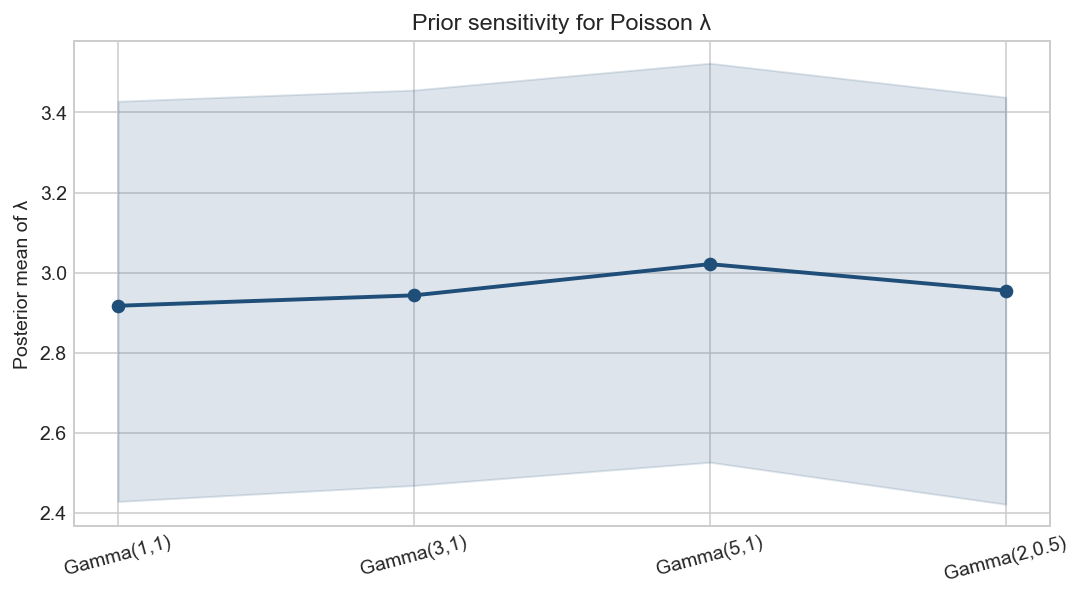

In [905]:
plt.show()  # prior sensitivity figure embedded from enhanced run


### Answer / Interpretation

    The posterior mean of λ stays near the data-driven value across several Gamma priors. That is a healthy sign: the demand conclusion is not an artifact of one aggressive prior. HDIs shift slightly, but the operational message (“a few requests per day”) remains stable.
    


## Case 12 — Outlier Influence on Resolution-Time Inference


In [906]:
influence_df


,dataset,mu_mean,sigma_mean,nu_mean
0,All observations (n=35),13.710,1.359,2.965
1,Without 42-min outlier (n=34),13.734,1.438,16.309


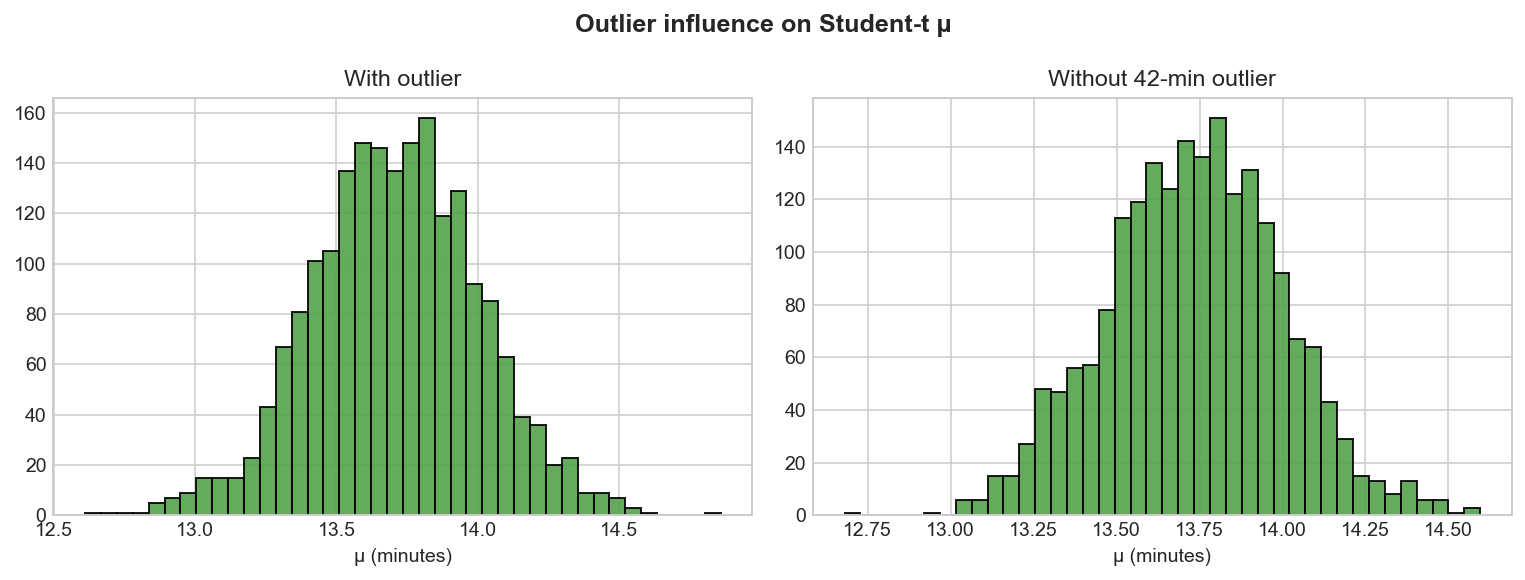

In [907]:
plt.show()  # outlier influence figure


### Answer / Interpretation

    Removing the 42-minute case changes the Student-*t* fit only modestly for μ, which is exactly what a robust likelihood should do. The practical message is that typical resolution time is governed by the main cluster near the low teens, while the long case is better treated as a rare escalation event than as the new normal.
    


## Case 13 — Staffing and Weekly Demand Decision Tools


In [908]:
staff_df


,threshold_k,P(Y >= k)
0,0,1.000
1,1,0.949
2,2,0.779
3,3,0.571
4,4,0.332
5,5,0.175
6,6,0.088
7,7,0.030
8,8,0.012
9,9,0.004


In [909]:
weekly_summary.to_frame('value')


,value
mean_weekly_requests,14.742
sd_weekly_requests,4.195
hdi_3%,7.000
hdi_97%,22.000
P(weekly >= 20),0.126
P(weekly >= 25),0.020


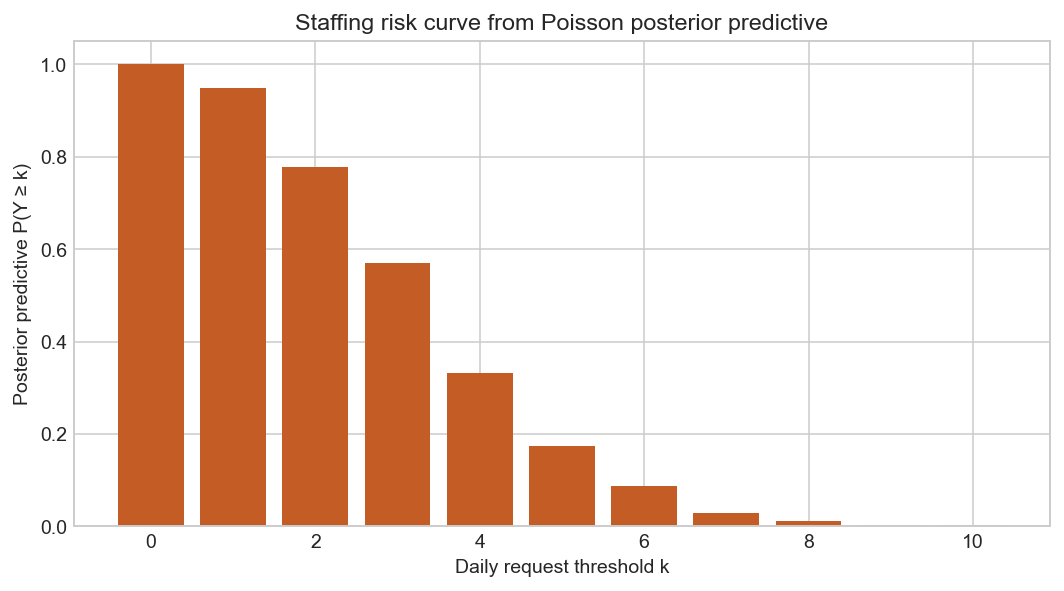

In [910]:
plt.show()  # staffing risk curve


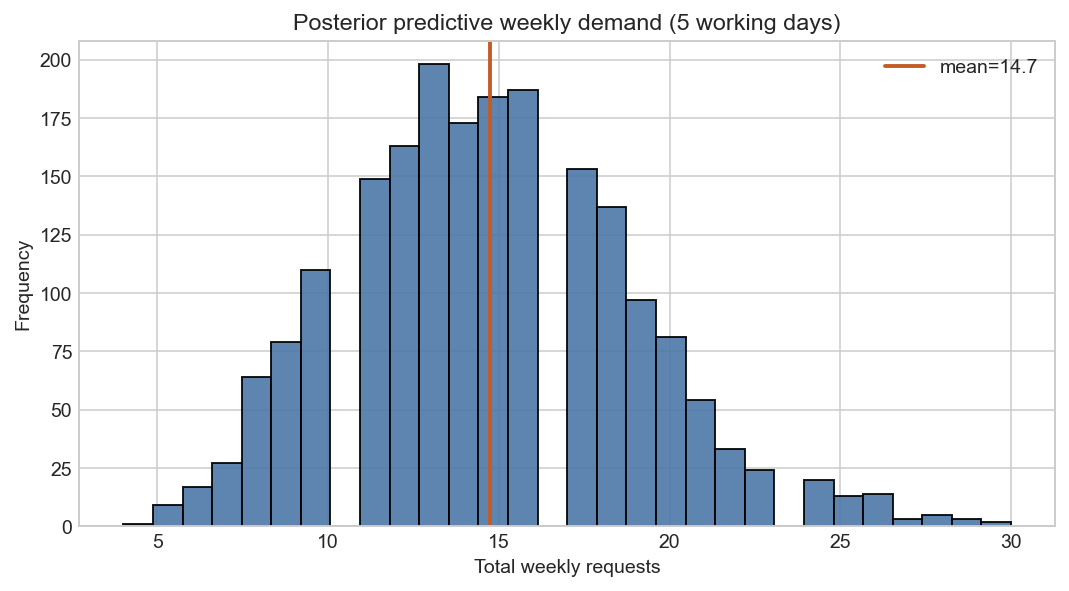

In [911]:
plt.show()  # weekly demand forecast


### Answer / Interpretation

    Instead of quoting only λ̂, we convert the posterior into decision curves:

    - **Daily staffing risk:** predictive probabilities that demand meets or exceeds threshold k.
    - **Weekly capacity:** five-day total demand distribution with mean about **14.742** requests and a 94% HDI of approximately **[7.0, 22.0]**.

    These quantities are easier for operations staff to use than a single rate parameter.
    


## Case 14 — Extended ROPE Sensitivity and Executive Dashboard


In [912]:
rope_df


,ROPE,mu_hdi_3%,mu_hdi_97%,decision
0,"[13.0, 15.0]",13.135,14.259,Accept practical equivalence
1,"[13.5, 14.5]",13.135,14.259,Undecided
2,"[13.8, 14.2]",13.135,14.259,Undecided
3,"[12.5, 15.5]",13.135,14.259,Accept practical equivalence


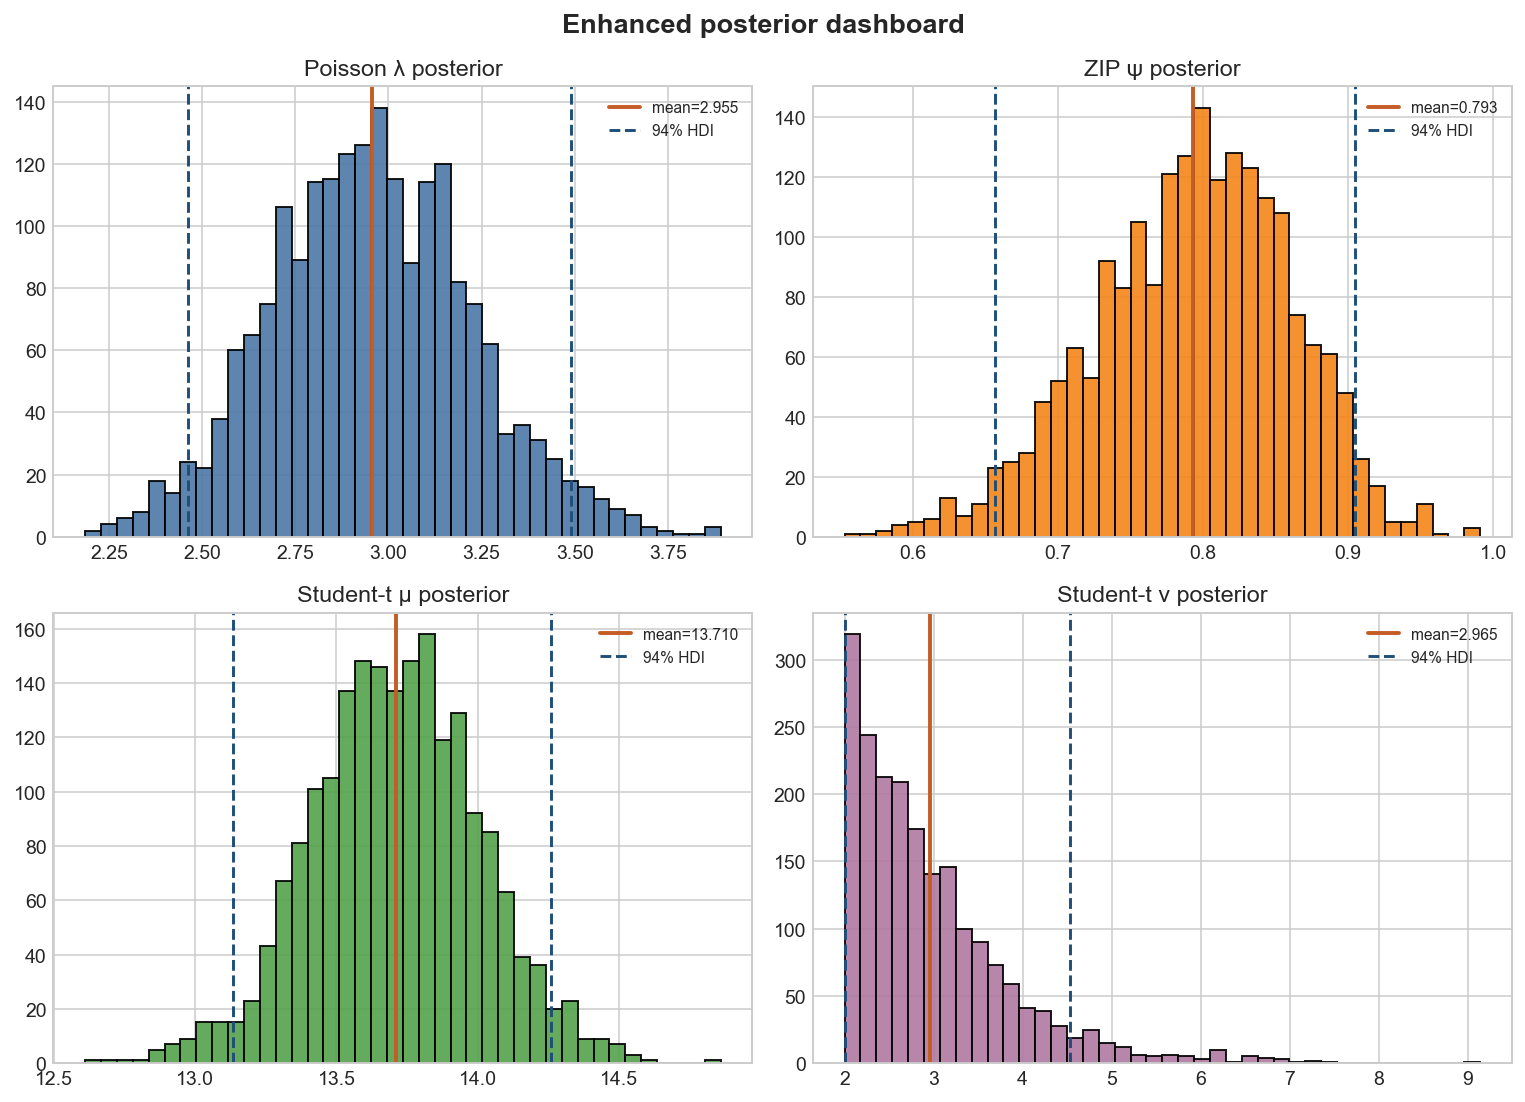

In [913]:
plt.show()  # executive posterior dashboard


### Answer / Interpretation

    The extended ROPE table shows that practical equivalence to the 14-minute benchmark is accepted only when the tolerance window is relatively wide. Under the assignment’s primary ROPE [13.5, 14.5], the decision remains **Undecided**. The executive dashboard compresses the main posteriors into one visual for viva or stakeholder review.
    


## Case 15 — Final Enhanced Synthesis

    | Question | Preferred evidence | Decision-ready statement |
    |---|---|---|
    | Typical daily demand | Poisson λ posterior + ZIP zero calibration | Expect about 3 requests/day; plan for zero-request days separately |
    | Are zeros special? | ZIP PPC + LOO | Yes — ordinary Poisson understates quiet days |
    | Typical resolution time | Student-*t* μ / σ / ν | Usual work completes near ~13.7 minutes |
    | Outlier policy | Influence analysis | Treat 42-min case as escalation, not the baseline |
    | 14-minute benchmark | ROPE sensitivity | Not settled under the default ROPE; needs clearer tolerance or more data |

    ### Reproducibility checklist
    - seed fixed at `RANDOM_SEED = 2026`
    - common `SAMPLE_KWARGS` for all models
    - portable PyTensor cache directory
    - helpers: `posterior_summary`, `rope_decision`, `quick_diag`
    - Pages-ready HTML export available from this notebook
    
